# 1. Import và valid file dữ liệu, quan sát dữ liệu thô

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

filename = "MILKY_Recovery_Labels_202603_202608.csv"

current_and_parents = [Path.cwd(), *Path.cwd().parents]

candidates = current_and_parents + [
    path / "recovery-brake" for path in current_and_parents
]

ROOT = next(
    (
        path for path in candidates
        if (path / "data" / filename).is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        f"Could not find {filename} in data/. "
        "Please check the CSV file location."
    )

DATA_PATH = ROOT / "data" / filename

print(f"Project data folder: {ROOT / 'data'}")
print(f"CSV file: {DATA_PATH}")

Project data folder: d:\Academic\UET\ATCS\shock-detector\data
CSV file: d:\Academic\UET\ATCS\shock-detector\data\MILKY_Recovery_Labels_202603_202608.csv


In [2]:
raw = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")

print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
print("Column names:", raw.columns.tolist())
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())

Rows: 14,045 | Columns: 6
Column names: ['timestamp', 'basket_id', 'side', 'Ri', 'timestamp_quality', 'tick_match_count']


,timestamp,basket_id,side,Ri,timestamp_quality,tick_match_count
0,2026-03-02 01:00:33.703,BMM8H21S1,BUY,1,EXACT_UNIQUE,1
1,2026-03-02 01:05:06.266,BMM8H21S1,BUY,2,EXACT_UNIQUE,1
2,2026-03-02 01:10:07.243,BMM8H21S1,BUY,3,EXACT_UNIQUE,1
3,2026-03-02 01:11:12.013,BMM8HEWQU,SELL,1,EXACT_AMBIGUOUS_FIRST,3
4,2026-03-02 01:15:01.665,BMM8H21S1,BUY,4,EXACT_UNIQUE,1


,dtype
timestamp,str
basket_id,str
side,str
Ri,int64
timestamp_quality,str
tick_match_count,int64


# 2. Chuẩn hóa các cột
Gồm timestamp, basket_id, side và Ri

In [3]:
required_columns = ["timestamp", "basket_id", "side", "Ri"]
missing_columns = [column for column in required_columns if column not in raw.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from CSV: {missing_columns}")

df = raw.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
ri_digits = df["Ri"].astype("string").str.extract(r"(\d+)", expand=False)
df["Ri"] = pd.to_numeric(ri_digits, errors="coerce")
df["basket_id"] = df["basket_id"].astype("string").str.strip()
df["side"] = df["side"].astype("string").str.strip().str.upper()

bad_timestamp = df["timestamp"].isna()
bad_ri = df["Ri"].isna()
print(f"Timestamps that could not be parsed: {bad_timestamp.sum()}")
print(f"Recovery levels that could not be parsed: {bad_ri.sum()}")
if bad_timestamp.any() or bad_ri.any():
    display(df.loc[bad_timestamp | bad_ri].head(10))
    raise ValueError("Fix or investigate invalid timestamps/recovery levels before continuing.")

df["Ri"] = df["Ri"].astype(int)
df = df.sort_values(["basket_id", "Ri"]).reset_index(drop=True)

print(f"Rows after parsing: {len(df):,}")
print(f"Unique baskets: {df['basket_id'].nunique():,}")
print(f"Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")
display(df.head())

Timestamps that could not be parsed: 0
Recovery levels that could not be parsed: 0
Rows after parsing: 14,045
Unique baskets: 6,081
Date range: 2026-03-02 01:00:33.703000 to 2026-08-31 21:01:08


,timestamp,basket_id,side,Ri,timestamp_quality,tick_match_count
0,2026-03-02 01:00:33.703,BMM8H21S1,BUY,1,EXACT_UNIQUE,1
1,2026-03-02 01:05:06.266,BMM8H21S1,BUY,2,EXACT_UNIQUE,1
2,2026-03-02 01:10:07.243,BMM8H21S1,BUY,3,EXACT_UNIQUE,1
3,2026-03-02 01:15:01.665,BMM8H21S1,BUY,4,EXACT_UNIQUE,1
4,2026-03-02 01:20:01.470,BMM8H21S1,BUY,5,EXACT_UNIQUE,1


# 3. Tạo bảng cho mỗi basket

Tạo bảng group theo mỗi mã basket, với các thông tin là bán/mua, thời gian bắt đầu/kết thúc, độ dài, và phân bố

In [4]:
baskets = (
    df.groupby("basket_id", as_index=False)
    .agg(
        side=("side", "first"),
        M=("Ri", "max"),
        t_start=("timestamp", "min"),
        t_end=("timestamp", "max"),
    )
)
baskets["month"] = baskets["t_start"].dt.to_period("M").astype(str)
baskets["duration_hours"] = (baskets["t_end"] - baskets["t_start"]).dt.total_seconds() / 3600

print(f"Number of baskets: {len(baskets):,}")
display(baskets.head())
display(baskets[["M", "duration_hours"]].describe().round(2))

Number of baskets: 6,081


,basket_id,side,M,t_start,t_end,month,duration_hours
0,BMM8H21S1,BUY,7,2026-03-02 01:00:33.703,2026-03-02 01:34:31.609,2026-03,0.566085
1,BMM8HEWQU,SELL,1,2026-03-02 01:11:12.013,2026-03-02 01:11:12.013,2026-03,0.000000
2,BMM8JK2JQ,SELL,2,2026-03-02 02:11:13.714,2026-03-02 02:15:22.470,2026-03,0.069099
3,BMM8JQI14,BUY,1,2026-03-02 02:16:01.607,2026-03-02 02:16:01.607,2026-03,0.000000
4,BMM8K3D00,SELL,1,2026-03-02 02:26:10.272,2026-03-02 02:26:10.272,2026-03,0.000000


,M,duration_hours
count,6081.00,6081.00
mean,2.31,0.22
std,3.13,1.24
min,1.00,0.00
25%,1.00,0.00
50%,1.00,0.00
75%,2.00,0.14
max,55.00,57.69


# 4. Validate chất lượng data

In [5]:
display(df.isna().sum().rename("missing_values").to_frame())

duplicate_pairs = int(df.duplicated(["basket_id", "Ri"]).sum())
per_basket_levels = df.groupby("basket_id")["Ri"].agg(["size", "min", "max"])
incomplete_sequences = int(
    ((per_basket_levels["min"] != 1) | (per_basket_levels["size"] != per_basket_levels["max"])).sum()
)
mixed_sides = int((df.groupby("basket_id")["side"].nunique() > 1).sum())
timestamp_differences = df.groupby("basket_id")["timestamp"].diff()
timestamp_out_of_order = int((timestamp_differences < pd.Timedelta(0)).sum())

ordered_baskets = baskets.sort_values(["side", "t_start"]).copy()
ordered_baskets["previous_max_end"] = ordered_baskets.groupby("side")["t_end"].transform(
    lambda end_times: end_times.cummax().shift()
)
same_side_overlaps = int((ordered_baskets["t_start"] < ordered_baskets["previous_max_end"]).sum())

quality_checks = pd.DataFrame(
    [
        ("Missing values in required columns", int(df[required_columns].isna().sum().sum())),
        ("Duplicate (basket_id, Ri) pairs", duplicate_pairs),
        ("Baskets with missing/nonconsecutive levels", incomplete_sequences),
        ("Baskets with more than one side", mixed_sides),
        ("Timestamps decreasing by recovery level", timestamp_out_of_order),
        ("Overlapping baskets on the same side", same_side_overlaps),
    ],
    columns=["check", "errors"],
)
display(quality_checks)

if "timestamp_quality" in df.columns:
    quality_counts = df["timestamp_quality"].value_counts(dropna=False).rename("rows").to_frame()
    quality_counts["share"] = quality_counts["rows"] / len(df)
    display(quality_counts)
else:
    print("No timestamp_quality column was present in the source CSV.")

,missing_values
timestamp,0
basket_id,0
side,0
Ri,0
timestamp_quality,0
tick_match_count,0


,check,errors
0,Missing values in required columns,0
1,"Duplicate (basket_id, Ri) pairs",0
2,Baskets with missing/nonconsecutive levels,0
3,Baskets with more than one side,0
4,Timestamps decreasing by recovery level,0
5,Overlapping baskets on the same side,0


,rows,share
timestamp_quality,,
EXACT_UNIQUE,9035,0.643289
EXACT_AMBIGUOUS_FIRST,2573,0.183197
REPORT_SECOND_ONLY,2437,0.173514


# 5. Phân bố độ sâu tối đa của basket

Cho rằng k=5

,baskets,median_depth,mean_depth,max_depth
side,,,,
BUY,2979,1.0,2.41,41
SELL,3102,1.0,2.22,55


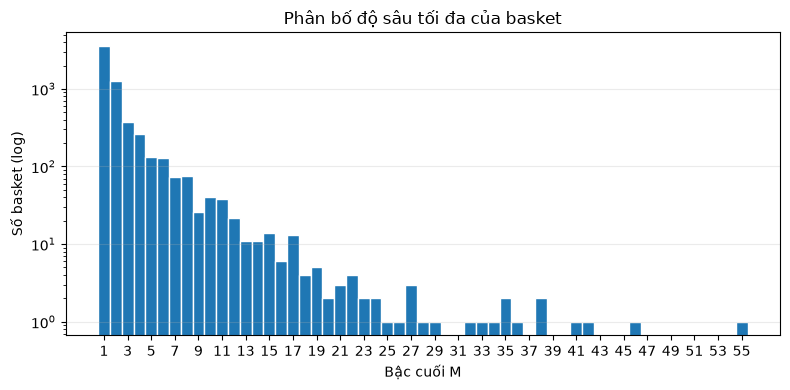

In [6]:
depth_by_side = (
    baskets.groupby("side")["M"]
    .agg(baskets="size", median_depth="median", mean_depth="mean", max_depth="max")
    .round(2)
)
display(depth_by_side)

fig, ax = plt.subplots(figsize=(8, 4))
depth_bins = np.arange(0.5, baskets["M"].max() + 1.5, 1)
ax.hist(baskets["M"], bins=depth_bins, edgecolor="white")
ax.set_yscale("log")
ax.set(title="Phân bố độ sâu tối đa của basket", xlabel="Bậc cuối M", ylabel="Số basket (log)")
ax.set_xticks(range(1, int(baskets["M"].max()) + 1, 2))
ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

# 6. Xác suất tiếp tục theo độ sâu

,k,n_reached_k,p_continue_1,p_continue_5
0,1,6081,0.415,0.082
1,2,2523,0.504,0.147
2,3,1272,0.704,0.234
3,4,896,0.705,0.249
4,5,632,0.790,0.312
5,6,499,0.745,0.313
6,7,372,0.801,0.317
7,8,298,0.748,0.322
8,9,223,0.883,0.381
9,10,197,0.792,0.376


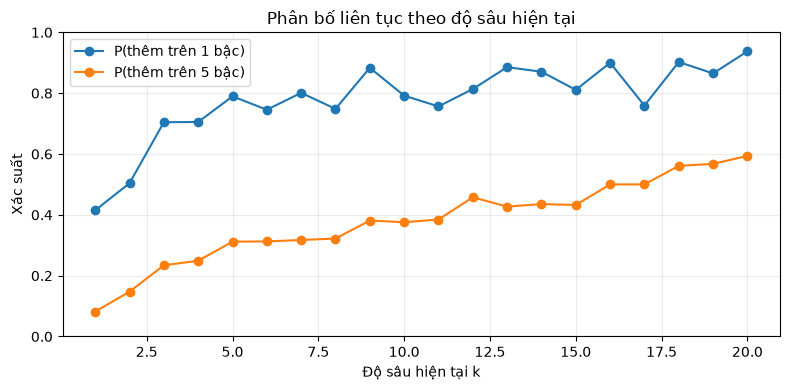

In [7]:
continuation_rows = []
for k in range(1, 21):
    reached_k = baskets["M"] >= k
    n_reached = int(reached_k.sum())
    if n_reached == 0:
        continue
    continuation_rows.append(
        {
            "k": k,
            "n_reached_k": n_reached,
            "p_continue_1": (baskets.loc[reached_k, "M"] >= k + 1).mean(),
            "p_continue_5": (baskets.loc[reached_k, "M"] >= k + 5).mean(),
        }
    )
continuation = pd.DataFrame(continuation_rows)
display(continuation.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(continuation["k"], continuation["p_continue_1"], marker="o", label="P(thêm trên 1 bậc)")
ax.plot(continuation["k"], continuation["p_continue_5"], marker="o", label="P(thêm trên 5 bậc)")
ax.set(title="Phân bố liên tục theo độ sâu hiện tại", xlabel="Độ sâu hiện tại k", ylabel="Xác suất")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 7. Thống kê theo tháng về số basket và độ sâu max

,baskets,buy_baskets,sell_baskets,median_depth,max_depth,reach_R10
month,,,,,,
2026-03,1484,713,771,1.0,38,0.027
2026-04,1043,537,506,1.0,36,0.035
2026-05,975,471,504,1.0,42,0.026
2026-06,932,450,482,1.0,41,0.038
2026-07,729,340,389,1.0,24,0.034
2026-08,918,468,450,1.0,55,0.039


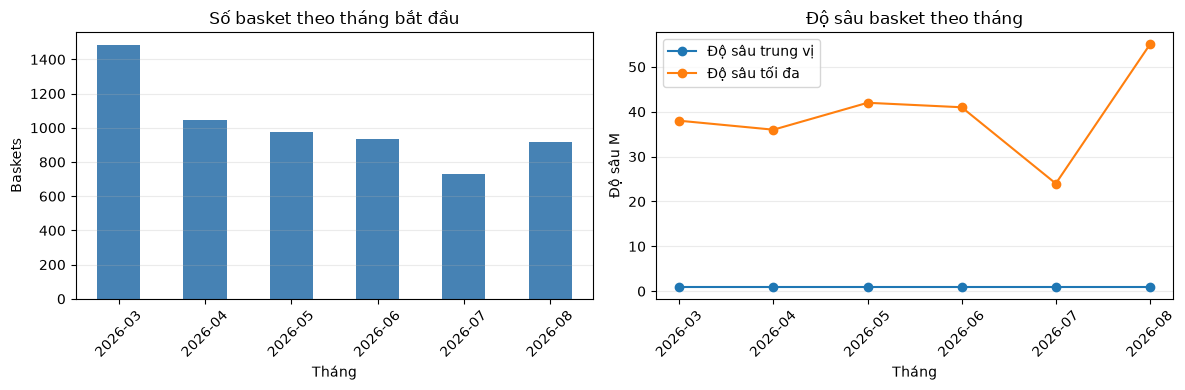

In [8]:
baskets["is_buy"] = baskets["side"].eq("BUY")
baskets["is_sell"] = baskets["side"].eq("SELL")
baskets["reached_R10"] = baskets["M"].ge(10)

monthly = (
    baskets.groupby("month")
    .agg(
        baskets=("M", "size"),
        buy_baskets=("is_buy", "sum"),
        sell_baskets=("is_sell", "sum"),
        median_depth=("M", "median"),
        max_depth=("M", "max"),
        reach_R10=("reached_R10", "mean"),
    )
)
display(monthly.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
monthly["baskets"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="Số basket theo tháng bắt đầu", xlabel="Tháng", ylabel="Baskets")
axes[0].tick_params(axis="x", rotation=45)
monthly[["median_depth", "max_depth"]].plot(marker="o", ax=axes[1])
axes[1].set(title="Độ sâu basket theo tháng", xlabel="Tháng", ylabel="Độ sâu M")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(["Độ sâu trung vị", "Độ sâu tối đa"])
for ax in axes:
    ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

# 8. Thời gian giữa các bậc recovery

Tính thời gian giữa 2 lần mở bậc liên tục trên 1 basket

,gap_minutes
count,7964.00
mean,10.27
std,53.49
min,0.25
25%,4.37
50%,5.80
75%,10.47
max,3331.96


,count,median,mean
Ri,,,
2,2523,5.05,7.13
3,1272,5.71,8.55
4,896,5.96,16.28
5,632,5.91,8.82
6,499,6.30,10.32
7,372,6.37,11.14
8,298,6.62,10.86
9,223,6.70,10.12
10,197,8.84,14.34


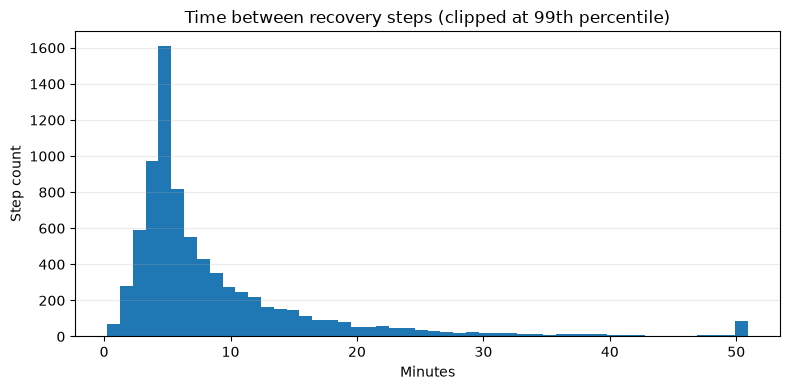

In [9]:
steps = df.sort_values(["basket_id", "Ri"]).copy()
steps["gap_minutes"] = (
    steps.groupby("basket_id")["timestamp"].diff().dt.total_seconds() / 60
)
step_gaps = steps.loc[steps["Ri"] >= 2, ["basket_id", "Ri", "timestamp", "gap_minutes"]].copy()

display(step_gaps["gap_minutes"].describe().to_frame().round(2))
display(
    step_gaps.groupby("Ri")["gap_minutes"]
    .agg(count="size", median="median", mean="mean")
    .head(20)
    .round(2)
)

upper_limit = step_gaps["gap_minutes"].quantile(0.99)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(step_gaps["gap_minutes"].clip(upper=upper_limit), bins=50)
ax.set(title="Time between recovery steps (clipped at 99th percentile)", xlabel="Minutes", ylabel="Step count")
ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

In [10]:
from types import SimpleNamespace

REQUIRED = ["timestamp", "basket_id", "side", "Ri"]
NS_PER_MIN = 60 * 10**9
C = SimpleNamespace(HORIZON=5, END_CUT_HOURS=24)

def load_labels(path):
    df = pd.read_csv(path, sep=";", encoding="utf-8-sig")
    if df.shape[1] == 1:                      # phòng trường hợp file dùng dấu phẩy
        df = pd.read_csv(path, sep=",", encoding="utf-8-sig")
    miss = [c for c in REQUIRED if c not in df.columns]
    if miss:
        raise ValueError(f"Thiếu cột {miss}; cột hiện có: {list(df.columns)}")
    ts = pd.to_datetime(df["timestamp"], errors="coerce")
    if ts.isna().any():
        raise ValueError(f"{int(ts.isna().sum())} timestamp không parse được")
    df["timestamp"] = ts.astype("datetime64[ns]")
    df["Ri"] = pd.to_numeric(df["Ri"].astype(str).str.extract(r"(\d+)")[0]).astype(int)
    df["side"] = df["side"].astype(str).str.upper().str.strip()
    df["basket_id"] = df["basket_id"].astype(str).str.strip()
    if "timestamp_quality" not in df.columns:
        df["timestamp_quality"] = "UNKNOWN"
    return df.sort_values(["basket_id", "Ri"]).reset_index(drop=True)


def build_samples(df, horizon=C.HORIZON, end_cut_hours=C.END_CUT_HOURS, eps=0.1):
    """Mỗi dòng = một lần bot sắp mở bậc Rk (k >= 2). Chỉ dùng thông tin có tại t_k.

    Họ 1 (trạng thái basket): logk, log_gap, accel, log_since_r1.
    Proxy từ nhãn (dự phòng nếu thiếu M1, KHÔNG dùng trong mô hình chính):
    n_rec_60m, opp_depth, opp_log_age. Các proxy này chỉ dùng sự kiện xảy ra TRƯỚC t_k.
    """
    d = df.sort_values(["basket_id", "Ri"]).copy()
    d["timestamp"] = d["timestamp"].astype("datetime64[ns]")
    g = d.groupby("basket_id")
    d["M"] = g["Ri"].transform("max")
    d["t1"] = g["timestamp"].transform("min")
    d["t_end"] = g["timestamp"].transform("max")
    d["gap_min"] = g["timestamp"].diff().dt.total_seconds() / 60
    d["gap_prev_min"] = d.groupby("basket_id")["gap_min"].shift(1)

    ts = d["timestamp"].values.astype("int64")
    all_ts = np.sort(ts)
    d["n_rec_60m"] = (np.searchsorted(all_ts, ts, "left")
                      - np.searchsorted(all_ts, ts - 60 * NS_PER_MIN, "left"))

    opp_depth = np.zeros(len(d))
    opp_age = np.full(len(d), 1440.0)
    sides = d["side"].values
    for s, o in (("BUY", "SELL"), ("SELL", "BUY")):
        ev = d[d["side"] == o].sort_values("timestamp")
        if ev.empty:
            continue
        ev_ts = ev["timestamp"].values.astype("int64")
        ev_ri = ev["Ri"].values
        m = sides == s
        idx = np.searchsorted(ev_ts, ts[m], "left") - 1
        ok = idx >= 0
        dep = np.where(ok, ev_ri[np.clip(idx, 0, None)], 0)
        age = np.where(ok, (ts[m] - ev_ts[np.clip(idx, 0, None)]) / NS_PER_MIN, 1440.0)
        opp_depth[m] = dep
        opp_age[m] = np.minimum(age, 1440.0)
    d["opp_depth"] = opp_depth
    d["opp_log_age"] = np.log1p(opp_age)

    data_end = d["timestamp"].max()
    cut = d["t_end"] > data_end - pd.Timedelta(hours=end_cut_hours)
    n_cut = int(d.loc[cut, "basket_id"].nunique())

    s = d[(d["Ri"] >= 2) & ~cut].copy()
    s["k"] = s["Ri"]
    s["y"] = ((s["M"] - s["k"]) >= horizon).astype(int)
    s["logk"] = np.log(s["k"])
    s["log_gap"] = np.log1p(s["gap_min"])
    s["accel"] = np.log((s["gap_min"] + eps) / (s["gap_prev_min"] + eps)).fillna(0.0)
    s["log_since_r1"] = np.log1p((s["timestamp"] - s["t1"]).dt.total_seconds() / 60)
    s["month"] = s["timestamp"].dt.to_period("M").astype(str)
    s["day"] = s["timestamp"].dt.floor("D")
    cols = ["basket_id", "side", "k", "timestamp", "month", "day", "M", "t_end", "y",
            "logk", "log_gap", "accel", "log_since_r1",
            "n_rec_60m", "opp_depth", "opp_log_age", "timestamp_quality"]
    info = dict(n_baskets_cut=n_cut, data_end=data_end,
                n_rows_all_k2=int((d["Ri"] >= 2).sum()), n_rows=len(s))
    return s[cols].reset_index(drop=True), info


labels_for_samples = load_labels(DATA_PATH)
samples, samples_info = build_samples(labels_for_samples)

INTERIM = ROOT / "data" / "interim"
INTERIM.mkdir(parents=True, exist_ok=True)
SAMPLES_PATH = INTERIM / "samples.parquet"
samples.to_parquet(SAMPLES_PATH, index=False)

print(f"All candidate k >= 2 rows before final-24h basket cut: {samples_info['n_rows_all_k2']:,}")
print(f"Rows saved after final-24h basket cut: {len(samples):,}")
print(f"Baskets cut at the data end: {samples_info['n_baskets_cut']:,}")
print(f"Positive rows: {int(samples['y'].sum()):,} ({samples['y'].mean():.4f})")
print(f"Unique baskets in samples: {samples['basket_id'].nunique():,}")
print(f"Saved G1 samples to: {SAMPLES_PATH}")
display(samples.head())


All candidate k >= 2 rows before final-24h basket cut: 7,964
Rows saved after final-24h basket cut: 7,889
Baskets cut at the data end: 66
Positive rows: 2,128 (0.2697)
Unique baskets in samples: 2,497
Saved G1 samples to: d:\Academic\UET\ATCS\shock-detector\data\interim\samples.parquet


,basket_id,side,k,timestamp,month,day,M,t_end,y,logk,log_gap,accel,log_since_r1,n_rec_60m,opp_depth,opp_log_age,timestamp_quality
0,BMM8H21S1,BUY,2,2026-03-02 01:05:06.266,2026-03,2026-03-02,7,2026-03-02 01:34:31.609,1,0.693147,1.712485,0.000000,1.712485,1,0.0,7.273093,EXACT_UNIQUE
1,BMM8H21S1,BUY,3,2026-03-02 01:10:07.243,2026-03,2026-03-02,7,2026-03-02 01:34:31.609,0,1.098612,1.794470,0.097129,2.356979,2,0.0,7.273093,EXACT_UNIQUE
2,BMM8H21S1,BUY,4,2026-03-02 01:15:01.665,2026-03,2026-03-02,7,2026-03-02 01:34:31.609,0,1.386294,1.776144,-0.021585,2.738646,4,1.0,1.574336,EXACT_UNIQUE
3,BMM8H21S1,BUY,5,2026-03-02 01:20:01.470,2026-03,2026-03-02,7,2026-03-02 01:34:31.609,0,1.609438,1.791218,0.017759,3.018608,5,1.0,2.284857,EXACT_UNIQUE
4,BMM8H21S1,BUY,6,2026-03-02 01:26:35.190,2026-03,2026-03-02,7,2026-03-02 01:34:31.609,0,1.791759,2.023136,0.267817,3.296754,6,1.0,2.796445,EXACT_UNIQUE
